# Question 2.5 — Catalan's constant

This notebook is an **exact certificate** for the finite algebraic claims used in the proof.  The integral/Laplace argument and the inverse-transpose theorem are written in the LaTeX text.  All assertions below use exact SymPy arithmetic; the final floating-point products are only a sanity check.

The original discovery notebook used `ramanujantools`.  A reconstruction cell is included at the end and runs automatically when that package is available.  The exact certificate itself is self-contained.

In [8]:
import sympy as sp
sp.init_printing()
n = sp.symbols('n')

def zero_matrix(A):
    return all(sp.cancel(x) == 0 for x in A)

print('SymPy', sp.__version__)


SymPy 1.13.3


## 1. Exact inverse-transpose identification

In [9]:
# Positive Meijer-G trajectory used in the analytic proof.
T = sp.Matrix([
[(8*n+16)*(17*n**3+111*n**2+240*n+171)/((n+1)*(2*n+3)*(2*n+5)*(2*n+6)),
 (n+2)*(24*n**2+101*n+102)/((n+1)*(2*n+3)),
 (n+2)*(2*n+5)*(16*n**2+81*n+90)/((n+1)*(4*n+6))],
[(384*n**4+3120*n**3+9536*n**2+13092*n+6892)/((n+1)*(n+2)*(n+3)*(2*n+3)*(8*n+20)),
 (136*n**3+796*n**2+1556*n+1046)/((n+1)*(n+2)*(8*n+12)),
 (192*n**4+1768*n**3+5940*n**2+8720*n+4806)/((n+1)*(n+2)*(16*n+24))],
[(-480*n**2-2340*n-2860)/((n+1)*(n+2)*(n+3)*(2*n+3)*(8*n+20)),
 (-160*n-410)/((n+1)*(n+2)*(8*n+12)),
 (16*n**3-88*n**2-956*n-1602)/((n+1)*(n+2)*(16*n+24))]
])

M = sp.Matrix([
[(-2*n-5)*(n+3)**2*(136*n**4+1424*n**3+5548*n**2+9551*n+6141),
 384*n**6+6384*n**5+44168*n**4+162698*n**3+336377*n**2+369933*n+169011,
 -480*n**4-4980*n**3-19210*n**2-32690*n-20730],
[(n+2)**2*(n+3)**2*(4*n+10)*(48*n**3+386*n**2+1017*n+879),
 (n+2)**2*(-272*n**5-3848*n**4-21732*n**3-61184*n**2-85761*n-47808),
 (n+2)**2*(320*n**3+2540*n**2+6610*n+5640)],
[(-4*n-10)*(n+2)**2*(n+3)**2*(32*n**4+302*n**3+1037*n**2+1530*n+813),
 (n+2)**2*(192*n**6+2984*n**5+19116*n**4+64452*n**3+120256*n**2+117279*n+46476),
 (n+2)**2*(-16*n**5-408*n**4-2912*n**3-8884*n**2-12254*n-6240)]
])

sigma = -2*(n+2)**2*(n+3)**2*(2*n+5)*(2*n+7)**2
assert zero_matrix(T.T*M - sigma*sp.eye(3))
print('PASS: M(n) = sigma(n) T(n)^(-T), including the absorbed stepwise sign.')

PASS: M(n) = sigma(n) T(n)^(-T), including the absorbed stepwise sign.


## 2. Companion coboundary and limiting characteristic polynomial

PASS: exact coboundary, determinant, and characteristic polynomial


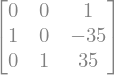

In [10]:
e0 = sp.Matrix([1,0,0])
U = sp.Matrix.hstack(e0, T*e0, T*T.subs(n,n+1)*e0)
C = (U.inv()*T*U.subs(n,n+1)).applyfunc(sp.cancel)
assert zero_matrix(T*U.subs(n,n+1)-U*C)
assert C[:,0] == sp.Matrix([0,1,0]) and C[:,1] == sp.Matrix([0,0,1])

Dpoly = 3072*n**7+61824*n**6+531184*n**5+2525522*n**4+7175793*n**3+12183785*n**2+11446123*n+4589916
expected_det = -15*Dpoly/(2*(n+1)*(n+2)**3*(n+3)**2*(n+4)*(2*n+3)**2*(2*n+5)**2*(2*n+7))
assert sp.cancel(U.det()-expected_det)==0

Cinf = C.applyfunc(lambda x: sp.limit(x,n,sp.oo))
lam = sp.symbols('lambda')
chi = sp.factor(Cinf.charpoly(lam).as_expr())
assert Cinf == sp.Matrix([[0,0,1],[1,0,-35],[0,1,35]])
assert sp.expand(chi-(lam-1)*(lam**2-34*lam+1))==0
print('PASS: exact coboundary, determinant, and characteristic polynomial')
display(Cinf, chi)

## 3. Saddle and recessive root

PASS: unique positive saddle p=sqrt(2)-1 and root rate mu=17-12*sqrt(2)


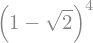

In [11]:
p = sp.symbols('p', positive=True)
h = p*(1-p)/(1+p)
t = sp.sqrt(2)-1
assert sp.simplify(sp.diff(h,p) + (p**2+2*p-1)/(p+1)**2) == 0
assert sp.simplify(sp.diff(h,p).subs(p,t))==0
mu = sp.simplify(t**4)
assert sp.simplify(mu-(17-12*sp.sqrt(2)))==0
assert sp.simplify((lam**2-34*lam+1).subs(lam,mu))==0
print('PASS: unique positive saddle p=sqrt(2)-1 and root rate mu=17-12*sqrt(2)')
display(mu)

## 4. Exact all-column connection coefficients

PASS: all three columns have nonzero recessive connection


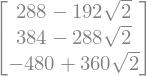

In [12]:
S = sp.diag(1,n,n**3)
Ulim = (S*U).applyfunc(lambda x: sp.limit(x,n,sp.oo))
expected_Ulim = sp.Matrix([[1,17,577],[0,24,816],[0,-30,-1020]])
assert Ulim == expected_Ulim
r = sp.Matrix([17+12*sp.sqrt(2),-18-12*sp.sqrt(2),1])
connections = [sp.simplify(Ulim.row(j).dot(r)) for j in range(3)]
expected = [96*(3-2*sp.sqrt(2)),96*(4-3*sp.sqrt(2)),120*(-4+3*sp.sqrt(2))]
assert all(sp.simplify(a-b)==0 for a,b in zip(connections,expected))
assert all(c != 0 for c in connections)
print('PASS: all three columns have nonzero recessive connection')
display(sp.Matrix(connections))

## 5. Companion initial vector and final cancellation

PASS: companion initial vector and A U(0)^(-T) F = 450 sqrt(pi) (G,1)^T


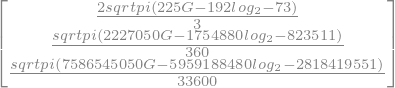

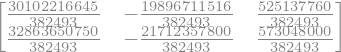

In [13]:
G, log2, sqrtpi = sp.symbols('G log2 sqrtpi')
Y0 = sp.Matrix([
 sqrtpi*(150*G-128*log2-sp.Rational(146,3)),
 sqrtpi/sp.Integer(6)*(1350*G-1344*log2-305),
 sqrtpi/sp.Integer(60)*(20250*G-24960*log2-1247)
])
U0 = U.subs(n,0)
Fvec = sp.simplify(U0.T*Y0)
expected_Fvec = sqrtpi*sp.Matrix([
 150*G-128*log2-sp.Rational(146,3),
 sp.Rational(24745,4)*G-sp.Rational(14624,3)*log2-sp.Rational(823511,360),
 sp.Rational(7225281,32)*G-sp.Rational(886784,5)*log2-sp.Rational(2818419551,33600)
])
assert all(sp.expand(a-b)==0 for a,b in zip(Fvec,expected_Fvec))

A = sp.Matrix([[30921,-32972,8240],[33750,-36000,9000]])
Acomp = sp.simplify(A*U0.inv().T)
expected_Acomp = sp.Rational(1,382493)*sp.Matrix([
[30102216645,-19896711516,525137760],
[32863650750,-21712357800,573048000]
])
assert Acomp == expected_Acomp
assert sp.simplify(Acomp*Fvec - 450*sqrtpi*sp.Matrix([G,1])) == sp.zeros(2,1)
print('PASS: companion initial vector and A U(0)^(-T) F = 450 sqrt(pi) (G,1)^T')
display(Fvec, Acomp)

## 6. RamanujanTools reconstruction of all package-generated matrices

When `ramanujantools` is available, the next cell reconstructs the Meijer--$G$ trajectory directly from the CMF parameters.  It then calls both `as_companion()` and `companion_coboundary_matrix()`, compares their outputs with the exact matrices used above (including the sign convention), and reconstructs the denominator-cleared inverse transpose that equals the challenge matrix.  Import failure is the only skipped case; any mathematical mismatch raises an assertion error.


In [14]:
try:
    from ramanujantools import Position
    from ramanujantools.cmf.meijer_g import MeijerG
except ImportError as exc:
    print(
        'RamanujanTools reconstruction skipped in this environment:',
        type(exc).__name__,
        exc,
    )
else:
    a0, a1, a2, a3, b0, b1, b2, b3 = sp.symbols(
        'a0 a1 a2 a3 b0 b1 b2 b3'
    )

    def normalize_rt_matrix(A):
        """Rewrite RamanujanTools' internal symbol named n as this notebook's n."""
        A = sp.Matrix(A)
        replacements = {s: n for s in A.free_symbols if s.name == 'n'}
        if replacements:
            A = A.xreplace(replacements)
        return A.applyfunc(sp.cancel)

    cmf_rt = MeijerG(4, 2, 4, 4, 1)
    direction_rt = Position({
        a0: -1, a1: -1, a2: 1, a3: 1,
        b0: 0, b1: 0, b2: 0, b3: 0,
    })
    initial_rt = Position({
        a0: -1, a1: -1,
        a2: sp.Rational(5, 2), a3: 3,
        b0: sp.Rational(3, 2), b1: sp.Rational(1, 2),
        b2: 1, b3: 0,
    })

    # Reconstruct every core object produced by RamanujanTools in the helper:
    # trajectory, companion matrix, companion coboundary, inverse transpose,
    # and the package's denominator-cleared polynomial normalization.
    T_rt_raw = cmf_rt.trajectory_matrix(direction_rt, initial_rt)
    C_rt_raw = T_rt_raw.as_companion().factor()
    U_rt_raw = T_rt_raw.companion_coboundary_matrix()
    TinvT_rt_raw = T_rt_raw.inv().T
    Mpoly_rt_raw = TinvT_rt_raw.as_polynomial().factor()

    T_rt = normalize_rt_matrix(T_rt_raw)
    C_rt = normalize_rt_matrix(C_rt_raw)
    U_rt = normalize_rt_matrix(U_rt_raw)
    TinvT_rt = normalize_rt_matrix(TinvT_rt_raw)
    Mpoly_rt = normalize_rt_matrix(Mpoly_rt_raw)

    # RamanujanTools uses the opposite stepwise sign from the positive
    # Meijer--G branch used in the analytic proof.  The diagonal sign gauge
    # converts the package companion data to the proof's convention.
    D = sp.diag(1, -1, 1)
    assert zero_matrix(T_rt + T), (
        'RamanujanTools Meijer--G trajectory differs from -T.'
    )
    assert zero_matrix(U_rt - U * D), (
        'RamanujanTools companion coboundary differs from U*diag(1,-1,1).'
    )
    assert zero_matrix(C_rt + D * C * D), (
        'RamanujanTools companion differs from -D*C*D.'
    )
    assert zero_matrix(
        T_rt * U_rt.subs(n, n + 1) - U_rt * C_rt
    ), 'RamanujanTools companion coboundary identity failed.'


    sigma_positive = (
        2 * (n + 2)**2 * (n + 3)**2 * (2*n + 5) * (2*n + 7)**2
    )
    assert zero_matrix(M - sigma_positive * TinvT_rt), (
        'The package inverse transpose does not reproduce the challenge matrix.'
    )
    assert zero_matrix(Mpoly_rt - M), (
        'RamanujanTools as_polynomial() does not equal the challenge matrix.'
    )

    print(
        'PASS: RamanujanTools reconstructs all Catalan proof matrices: '
        'trajectory, companion matrix, companion coboundary, inverse '
        'transpose, polynomial normalization, and the exact coboundary identity.'
    )


PASS: RamanujanTools reconstructs all Catalan proof matrices: trajectory, companion matrix, companion coboundary, inverse transpose, polynomial normalization, and the exact coboundary identity.
